# D&D Beyond Player Data vs. Simulation

The D&D Beyond 2023 Unrolled report provides ordinal rankings of class and species popularity across millions of real player characters. This notebook compares those player rankings against the simulation's rank ordering to identify where mechanical structure and player preference align — and where they diverge.

**Key caveat:** D&D Beyond reflects *all* published 5e content, not just the 2014 PHB. The class list is comparable (same 12 core classes + Artificer from Tasha's), but the species list includes many post-2014 options (Genasi, Goliath, Aasimar, etc.) not modeled in the simulation. Species comparisons are therefore limited to species present in both datasets.

**Data source:** D&D Beyond, *2023 Unrolled: A Look Back at a Year of Adventure* (2024). Rankings only — no percentages were published.

In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import stats as scipy_stats

## 1. Load Simulation Results

In [2]:
with open('sim_results.pkl', 'rb') as f:
    sim_results = pickle.load(f)

# Extract class and species counts (indices 1 and 0)
class_counts  = [run[1] for run in sim_results]
species_counts = [run[0] for run in sim_results]

all_classes  = sorted(set(k for run in class_counts  for k in run.keys()))
all_species  = sorted(set(k for run in species_counts for k in run.keys()))

class_df   = pd.DataFrame([{cls: run.get(cls, 0)  for cls in all_classes}  for run in class_counts])
species_df = pd.DataFrame([{sp:  run.get(sp, 0)   for sp  in all_species}  for run in species_counts])

n_chars = class_df.sum(axis=1).iloc[0]
class_pct   = class_df   / n_chars * 100
species_pct = species_df / n_chars * 100

# Simulation mean percentages and ranks
sim_class_means   = class_pct.mean().sort_values(ascending=False)
sim_species_means = species_pct.mean().sort_values(ascending=False)

print(f"Simulation: {len(sim_results)} runs x {int(n_chars):,} characters")
print("\nSimulation class ranking:")
for i, (cls, pct) in enumerate(sim_class_means.items(), 1):
    print(f"  {i:2d}. {cls:<12} {pct:.2f}%")

Simulation: 50 runs x 10,000 characters

Simulation class ranking:
   1. Fighter      24.86%
   2. Ranger       13.47%
   3. Cleric       10.75%
   4. Paladin      9.51%
   5. Wizard       7.84%
   6. Sorcerer     7.19%
   7. Monk         5.56%
   8. Rogue        5.16%
   9. Barbarian    4.44%
  10. Warlock      4.02%
  11. Bard         4.02%
  12. Druid        3.20%


## 2. D&D Beyond Rankings

Ordinal rankings from the 2023 Unrolled report. Artificer (Tasha's) is excluded from class comparison to keep to the 2014 PHB scope. Species comparison is limited to PHB species present in the D&D Beyond list.

In [3]:
# D&D Beyond 2023 class rankings (ordinal, 1 = most popular)
# Source: dndbeyond.com/posts/1648-2023-unrolled-a-look-back-at-a-year-of-adventure
# Artificer excluded (not in 2014 PHB)
dndb_class_rank = {
    'Fighter':   1,
    'Rogue':     2,
    'Barbarian': 3,
    'Wizard':    4,
    'Paladin':   5,
    'Warlock':   6,
    'Cleric':    7,
    'Ranger':    8,
    'Bard':      9,
    'Druid':     10,
    'Sorcerer':  11,
    'Monk':      12,
}

# D&D Beyond 2023 species rankings (ordinal)
# Only PHB 2014 species included; Elf is listed as a single category (combining High/Wood/Drow)
dndb_species_rank = {
    'Human':      1,
    'Elf':        2,   # aggregate — maps to High/Wood/Drow combined in simulation
    'Dragonborn': 3,
    'Tiefling':   4,
    'Half-Elf':   5,
    'Dwarf':      6,   # aggregate — maps to Hill/Mountain combined
    'Halfling':   7,   # aggregate — maps to Lightfoot/Stout combined
    'Half-Orc':   8,
    'Gnome':      9,   # aggregate — maps to Rock/Forest combined
}

print("D&D Beyond class ranking loaded:", sorted(dndb_class_rank.items(), key=lambda x: x[1]))

D&D Beyond class ranking loaded: [('Fighter', 1), ('Rogue', 2), ('Barbarian', 3), ('Wizard', 4), ('Paladin', 5), ('Warlock', 6), ('Cleric', 7), ('Ranger', 8), ('Bard', 9), ('Druid', 10), ('Sorcerer', 11), ('Monk', 12)]


## 3. Class Rank Comparison

In [4]:
# Simulation ranks for the 12 classes
sim_class_rank = {
    cls: int(rank) 
    for rank, cls in enumerate(
        sim_class_means[list(dndb_class_rank.keys())].sort_values(ascending=False).index, 1
    )
}

class_comparison = pd.DataFrame({
    'D&D Beyond rank': dndb_class_rank,
    'Simulation rank': sim_class_rank,
    'Simulation %':    sim_class_means[list(dndb_class_rank.keys())].round(2),
}).sort_values('D&D Beyond rank')

class_comparison['Rank Δ'] = (
    class_comparison['Simulation rank'] - class_comparison['D&D Beyond rank']
)

print(class_comparison.to_string())

# Spearman correlation
rho, p = scipy_stats.spearmanr(
    class_comparison['D&D Beyond rank'],
    class_comparison['Simulation rank']
)
print(f"\nSpearman ρ = {rho:.3f}, p = {p:.4f}")

           D&D Beyond rank  Simulation rank  Simulation %  Rank Δ
Fighter                  1                1         24.86       0
Rogue                    2                8          5.16       6
Barbarian                3                9          4.44       6
Wizard                   4                5          7.84       1
Paladin                  5                4          9.51      -1
Warlock                  6               10          4.02       4
Cleric                   7                3         10.75      -4
Ranger                   8                2         13.47      -6
Bard                     9               11          4.02       2
Druid                   10               12          3.20       2
Sorcerer                11                6          7.19      -5
Monk                    12                7          5.56      -5

Spearman ρ = 0.301, p = 0.3423


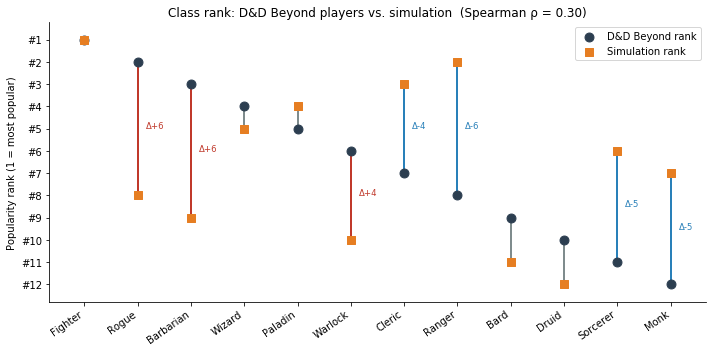

Saved to figs/dndbeyond_class_comparison.png


In [5]:
# --- Class rank comparison plot ---
n = len(dndb_class_rank)
classes_by_dndb = class_comparison.index.tolist()

dndb_ranks = class_comparison['D&D Beyond rank'].values
sim_ranks  = class_comparison['Simulation rank'].values
deltas     = class_comparison['Rank Δ'].values

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(n)
colors = ['#c0392b' if d > 2 else '#2980b9' if d < -2 else '#7f8c8d' for d in deltas]

ax.scatter(x, dndb_ranks, marker='o', s=80, color='#2c3e50', zorder=4, label='D&D Beyond rank')
ax.scatter(x, sim_ranks,  marker='s', s=80, color='#e67e22', zorder=4, label='Simulation rank')

for i in range(n):
    ax.plot([x[i], x[i]], [dndb_ranks[i], sim_ranks[i]],
            color=colors[i], linewidth=2, zorder=3)

ax.set_xticks(x)
ax.set_xticklabels(classes_by_dndb, rotation=35, ha='right')
ax.set_yticks(range(1, n + 1))
ax.set_yticklabels([f"#{i}" for i in range(1, n + 1)])
ax.invert_yaxis()
ax.set_ylabel('Popularity rank (1 = most popular)')
ax.set_title(
    f'Class rank: D&D Beyond players vs. simulation  (Spearman ρ = {rho:.2f})'
)
ax.legend(loc='upper right')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# Annotate large divergences
for i, cls in enumerate(classes_by_dndb):
    if abs(deltas[i]) > 3:
        mid = (dndb_ranks[i] + sim_ranks[i]) / 2
        ax.annotate(f"Δ{deltas[i]:+d}",
                    xy=(x[i] + 0.15, mid), fontsize=8.5, color=colors[i])

plt.tight_layout()
plt.savefig('figs/dndbeyond_class_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to figs/dndbeyond_class_comparison.png")

## 4. Species Rank Comparison

D&D Beyond aggregates elves, dwarves, halflings, and gnomes. We aggregate the corresponding simulation sub-species for a fair comparison.

In [6]:
# Map D&D Beyond aggregated species to simulation sub-species
species_agg_map = {
    'Human':      ['Human', 'Human Variant'],
    'Elf':        ['Elf (High)', 'Elf (Wood)', 'Elf (Drow)'],
    'Dragonborn': ['Dragonborn'],
    'Tiefling':   ['Tiefling'],
    'Half-Elf':   ['Half-Elf'],
    'Dwarf':      ['Dwarf (Hill)', 'Dwarf (Mountain)'],
    'Halfling':   ['Halfling (Lightfoot)', 'Halfling (Stout)'],
    'Half-Orc':   ['Half-Orc'],
    'Gnome':      ['Gnome (Rock)', 'Gnome (Forest)'],
}

# Aggregate simulation percentages
sim_species_agg = {}
for group, members in species_agg_map.items():
    present = [m for m in members if m in species_pct.columns]
    sim_species_agg[group] = species_pct[present].sum(axis=1).mean()

sim_species_agg_series = pd.Series(sim_species_agg).sort_values(ascending=False)
sim_species_rank_agg = {
    sp: int(rank)
    for rank, sp in enumerate(sim_species_agg_series.index, 1)
}

species_comparison = pd.DataFrame({
    'D&D Beyond rank': dndb_species_rank,
    'Simulation rank': sim_species_rank_agg,
    'Simulation %':    sim_species_agg_series.round(2),
}).sort_values('D&D Beyond rank')

species_comparison['Rank Δ'] = (
    species_comparison['Simulation rank'] - species_comparison['D&D Beyond rank']
)

print(species_comparison.to_string())

rho_sp, p_sp = scipy_stats.spearmanr(
    species_comparison['D&D Beyond rank'],
    species_comparison['Simulation rank']
)
print(f"\nSpearman ρ = {rho_sp:.3f}, p = {p_sp:.4f}")

            D&D Beyond rank  Simulation rank  Simulation %  Rank Δ
Human                     1                1         21.51       0
Elf                       2                2         20.18       0
Dragonborn                3                8          5.87       5
Tiefling                  4                9          3.35       5
Half-Elf                  5                3         15.33      -2
Dwarf                     6                4         10.08      -2
Halfling                  7                5          8.65      -2
Half-Orc                  8                7          6.41      -1
Gnome                     9                6          8.62      -3

Spearman ρ = 0.400, p = 0.2861


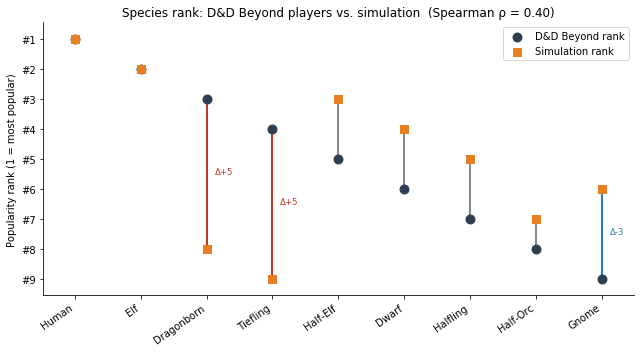

Saved to figs/dndbeyond_species_comparison.png


In [7]:
n_sp = len(dndb_species_rank)
species_by_dndb = species_comparison.index.tolist()

dndb_sp_ranks = species_comparison['D&D Beyond rank'].values
sim_sp_ranks  = species_comparison['Simulation rank'].values
sp_deltas     = species_comparison['Rank Δ'].values

sp_colors = ['#c0392b' if d > 2 else '#2980b9' if d < -2 else '#7f8c8d' for d in sp_deltas]

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(n_sp)
ax.scatter(x, dndb_sp_ranks, marker='o', s=80, color='#2c3e50', zorder=4, label='D&D Beyond rank')
ax.scatter(x, sim_sp_ranks,  marker='s', s=80, color='#e67e22', zorder=4, label='Simulation rank')

for i in range(n_sp):
    ax.plot([x[i], x[i]], [dndb_sp_ranks[i], sim_sp_ranks[i]],
            color=sp_colors[i], linewidth=2, zorder=3)

ax.set_xticks(x)
ax.set_xticklabels(species_by_dndb, rotation=35, ha='right')
ax.set_yticks(range(1, n_sp + 1))
ax.set_yticklabels([f"#{i}" for i in range(1, n_sp + 1)])
ax.invert_yaxis()
ax.set_ylabel('Popularity rank (1 = most popular)')
ax.set_title(
    f'Species rank: D&D Beyond players vs. simulation  (Spearman ρ = {rho_sp:.2f})'
)
ax.legend(loc='upper right')
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

for i, sp in enumerate(species_by_dndb):
    if abs(sp_deltas[i]) > 2:
        mid = (dndb_sp_ranks[i] + sim_sp_ranks[i]) / 2
        ax.annotate(f"Δ{sp_deltas[i]:+d}",
                    xy=(x[i] + 0.12, mid), fontsize=8.5, color=sp_colors[i])

plt.tight_layout()
plt.savefig('figs/dndbeyond_species_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to figs/dndbeyond_species_comparison.png")

## 5. Key Divergences — Interpretation

Classes or species with |Rank Δ| > 3 are candidates for discussion in the paper. The pattern of divergences tells us which choices are mechanically driven vs. aesthetically driven.

In [8]:
print("=== CLASS DIVERGENCES (|Δ| > 2) ===")
print("Δ = Simulation rank − D&D Beyond rank")
print("Negative Δ → mechanics overrepresent (sim rank < player rank → mechanics predict MORE popularity)")
print("Positive Δ → mechanics underrepresent (sim rank > player rank → mechanics predict LESS popularity)")
print()
large_class_div = class_comparison[class_comparison['Rank Δ'].abs() > 2].sort_values('Rank Δ')
for cls, row in large_class_div.iterrows():
    if row['Rank Δ'] < 0:
        direction = "OVERREPRESENTED by mechanics (mechanics predict more than players choose)"
    else:
        direction = "UNDERREPRESENTED by mechanics (players choose more than mechanics predict)"
    print(f"  {cls}: D&D Beyond #{int(row['D&D Beyond rank'])}, Simulation #{int(row['Simulation rank'])} "
          f"(Δ = {row['Rank Δ']:+.0f}) — {direction}")

print()
print("=== SPECIES DIVERGENCES (|Δ| > 2) ===")
large_sp_div = species_comparison[species_comparison['Rank Δ'].abs() > 2].sort_values('Rank Δ')
for sp, row in large_sp_div.iterrows():
    if row['Rank Δ'] < 0:
        direction = "OVERREPRESENTED by mechanics (mechanics predict more than players choose)"
    else:
        direction = "UNDERREPRESENTED by mechanics (players choose more than mechanics predict)"
    print(f"  {sp}: D&D Beyond #{int(row['D&D Beyond rank'])}, Simulation #{int(row['Simulation rank'])} "
          f"(Δ = {row['Rank Δ']:+.0f}) — {direction}")

print()
print(f"Overall class Spearman ρ = {rho:.3f} (p = {p:.4f})")
print(f"Overall species Spearman ρ = {rho_sp:.3f} (p = {p_sp:.4f})")
print()
print("Interpretation:")
print("  Low ρ, non-significant → mechanics do not reliably predict player preferences")
print("  Large negative Δ → mechanics overpredict; players avoid despite mechanical fitness (e.g. Ranger)")
print("  Large positive Δ → aesthetic/narrative appeal overrides mechanical disadvantage (e.g. Rogue, Tiefling)")

=== CLASS DIVERGENCES (|Δ| > 2) ===
Δ = Simulation rank − D&D Beyond rank
Negative Δ → mechanics overrepresent (sim rank < player rank → mechanics predict MORE popularity)
Positive Δ → mechanics underrepresent (sim rank > player rank → mechanics predict LESS popularity)

  Ranger: D&D Beyond #8, Simulation #2 (Δ = -6) — OVERREPRESENTED by mechanics (mechanics predict more than players choose)
  Sorcerer: D&D Beyond #11, Simulation #6 (Δ = -5) — OVERREPRESENTED by mechanics (mechanics predict more than players choose)
  Monk: D&D Beyond #12, Simulation #7 (Δ = -5) — OVERREPRESENTED by mechanics (mechanics predict more than players choose)
  Cleric: D&D Beyond #7, Simulation #3 (Δ = -4) — OVERREPRESENTED by mechanics (mechanics predict more than players choose)
  Warlock: D&D Beyond #6, Simulation #10 (Δ = +4) — UNDERREPRESENTED by mechanics (players choose more than mechanics predict)
  Rogue: D&D Beyond #2, Simulation #8 (Δ = +6) — UNDERREPRESENTED by mechanics (players choose more tha